# SnapWave: how the template configuration was chosen

Netherlands, 2013, build `snapwave/b663c81-wind1` (GeoOcean wind fixes on upstream
`b663c81`). The same 27 buoys and 39 test hours as the SWAN notebook, the new WHACS_cal
forcing; 40 metamodel cases against SWAN (`OFF WCAP`, friction 0.038); 24 of the
hours where wind mode did not converge; and the convergence of all 8760 production
hours of 2013. Numbers from `results/*.csv`.

In [1]:
import pandas as pd
from IPython.display import Image, display

import decisions as d

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 250)

## 1. Boundary enclosure

SnapWave forces every mesh edge node inside `encfile` (the manual: the enclosure must
"limit the boundary points to those on the outer edge of the mesh that are at sea").
HyWaves used the minimum rectangle around the AoI, which held the whole mesh, so the
coast was forced with the goal spectra and radiated energy into the domain. Now
`bluemath_tk.topo_bathy.mesh.open_boundary_nodes` takes the outline through the goals,
out to where the lateral boundaries meet the coast (two corners), and
`open_boundary_enclosure` puts a thin polygon around it: 768 nodes, the 767 of SWAN's
`.grd` open boundary plus one corner node.

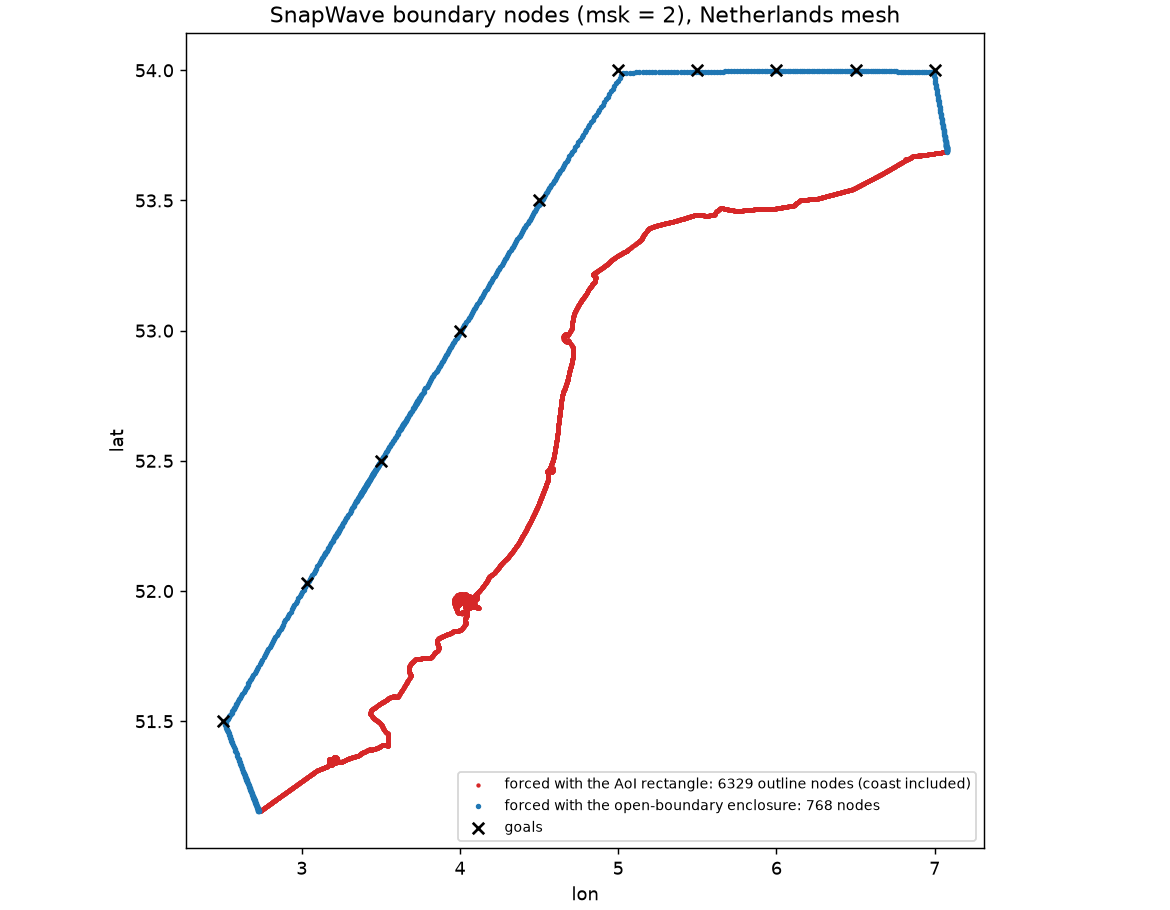

In [2]:
display(Image(filename="results/figures/snapwave_enclosure.png", width=650))

## 2. Dynamic runs at the buoys

AoI rectangle → open-boundary enclosure → plus upwind refraction (`upwindref = 1`),
then bottom friction `fw` and no wind on top. SWAN (Komen, WHACS_cal, friction 0.038)
for reference.

In [3]:
d.buoy_table("snapwave_setup")

label,"SnapWave (WHACS_cal), AoI rectangle","SnapWave (WHACS_cal), open-boundary enclosure","SnapWave (WHACS_cal), enclosure + upwindref 1","SnapWave (WHACS_cal), enclosure + upwindref 1, fw 0.02","SnapWave (WHACS_cal), enclosure + upwindref 1, fw 0.04","SnapWave no wind (WHACS_cal), enclosure + upwindref 1",SWAN Komen (WHACS_cal)
group,,,,,,,
calm,+0.27 / 0.35 (198),+0.23 / 0.32 (198),+0.21 / 0.31 (198),+0.19 / 0.30 (198),+0.16 / 0.28 (198),-0.18 / 0.34 (198),+0.03 / 0.17 (198)
storm,+0.22 / 0.41 (479),+0.20 / 0.41 (479),+0.15 / 0.39 (479),+0.01 / 0.35 (479),-0.20 / 0.43 (479),-0.28 / 0.44 (479),-0.14 / 0.35 (479)
xaver,-0.26 / 0.65 (175),-0.29 / 0.65 (175),-0.32 / 0.66 (175),-0.51 / 0.79 (175),-0.80 / 1.06 (175),-0.82 / 0.98 (175),-0.40 / 0.62 (175)
obs 0-1 m,+0.29 / 0.37 (125),+0.23 / 0.31 (125),+0.21 / 0.30 (125),+0.19 / 0.29 (125),+0.16 / 0.28 (125),-0.10 / 0.22 (125),+0.09 / 0.18 (125)
obs 1-2 m,+0.30 / 0.39 (188),+0.24 / 0.36 (188),+0.21 / 0.33 (188),+0.14 / 0.28 (188),+0.05 / 0.25 (188),-0.29 / 0.44 (188),+0.00 / 0.21 (188)
obs 2-3 m,+0.27 / 0.41 (226),+0.26 / 0.42 (226),+0.20 / 0.38 (226),+0.04 / 0.33 (226),-0.17 / 0.39 (226),-0.25 / 0.41 (226),-0.09 / 0.32 (226)
obs 3-4 m,+0.06 / 0.39 (203),+0.06 / 0.39 (203),+0.02 / 0.40 (203),-0.14 / 0.43 (203),-0.37 / 0.57 (203),-0.42 / 0.59 (203),-0.27 / 0.41 (203)
obs 4-5 m,-0.25 / 0.58 (74),-0.25 / 0.58 (74),-0.28 / 0.62 (74),-0.49 / 0.73 (74),-0.78 / 0.95 (74),-0.79 / 0.96 (74),-0.44 / 0.59 (74)
obs 5-6 m,-0.83 / 0.94 (7),-0.83 / 0.94 (7),-0.84 / 0.94 (7),-1.00 / 1.08 (7),-1.27 / 1.34 (7),-1.12 / 1.19 (7),-0.58 / 0.68 (7)


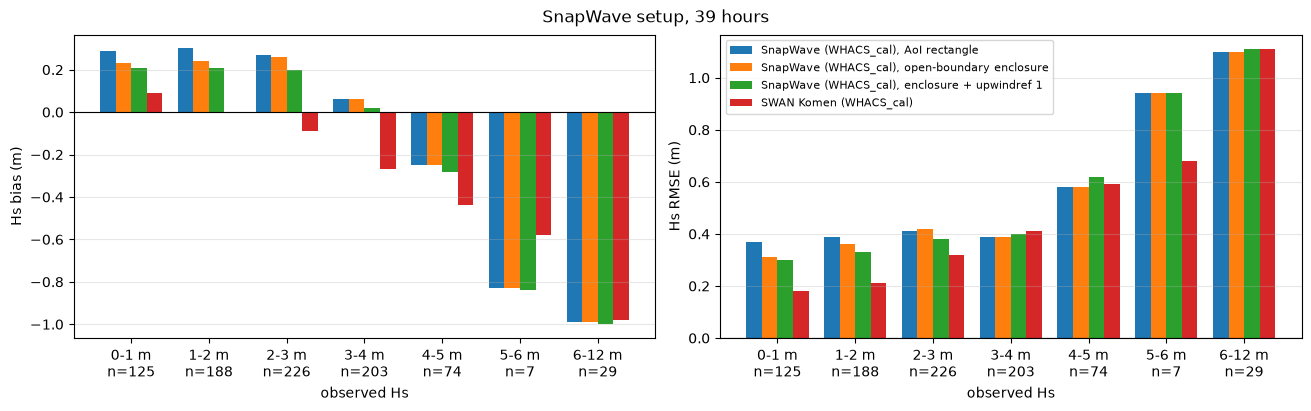

In [4]:
d.plot_by_class(
    "snapwave_setup",
    ["SnapWave (WHACS_cal), AoI rectangle", "SnapWave (WHACS_cal), open-boundary enclosure",
     "SnapWave (WHACS_cal), enclosure + upwindref 1", "SWAN Komen (WHACS_cal)"],
    "SnapWave setup, 39 hours",
);

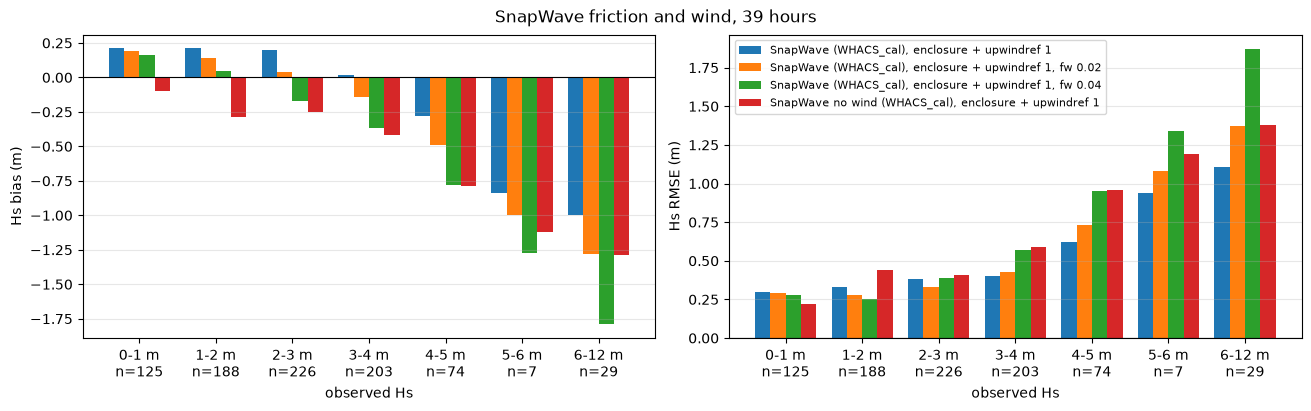

In [5]:
d.plot_by_class(
    "snapwave_setup",
    ["SnapWave (WHACS_cal), enclosure + upwindref 1", "SnapWave (WHACS_cal), enclosure + upwindref 1, fw 0.02",
     "SnapWave (WHACS_cal), enclosure + upwindref 1, fw 0.04", "SnapWave no wind (WHACS_cal), enclosure + upwindref 1"],
    "SnapWave friction and wind, 39 hours",
);

**Decisions.**

- **Enclosure**: correct by construction; at the buoys calm RMSE 0.35 → 0.32, depth
  < 15 m bias +0.11 → +0.06.
- **`upwindref = 1`** (monotone refraction): storm bias +0.20 → +0.15; Xaver slightly
  worse (−0.29 → −0.32).
- **`fw` stays at the default 0.01**: 0.02 fixes moderate seas but worsens storms
  (Xaver RMSE 0.66 → 0.79); 0.04 helps calm hours more and ruins storms (Xaver 1.06).
- **The positive bias is SnapWave's wind input**: without wind SnapWave matches SWAN
  (calm bias −0.18 vs −0.20 for SWAN); with wind it adds ~0.4 m in calm hours where
  SWAN adds ~0.2. That lives in the source's growth curves, not in a setting; any wind
  correction learned from SnapWave with/without wind inherits it.

## 3. Goal cases: refraction, iterations, sector

Hs ratio SnapWave / SWAN (`OFF WCAP`) on the 40 metamodel cases.

In [6]:
d.ratio_table("snapwave_setup")

variant          SnapWave production  SnapWave enclosure  SnapWave enclosure, niter 200  SnapWave enclosure + upwindref 1, niter 200  SnapWave enclosure, sector 360, niter 200
steepness where                                                                                                                                                                
0.00-0.02 <18m                 1.179               1.168                          1.168                                        1.035                                      1.171
          deep                 1.096               1.089                          1.089                                        1.029                                      1.089
0.02-0.04 <18m                 1.023               1.009                          1.009                                        0.941                                      1.009
          deep                 0.991               0.987                          0.987                                        0.935                                      0.988
0.04-0.07 <18m                 1.064               1.042                          1.042                                        0.973                                      1.043
          deep                 1.049               1.038                          1.038                                        0.983                                      1.038

**Decisions.** The enclosure lowers Hs near the coast (mean −0.012 m, p1 −0.30 m over
all sites). Upwind refraction brings gentle seas from 1.09–1.17 to 1.03 of SWAN and
makes **every** goal case converge (largest final error 1e-5; with the central scheme
7 of 40 ended above 0.01, one at 0.999). `niter` counts sweeps (4 per iteration):
200 instead of 40 changes Hs by ≤ 0.005 m (p99) but lets upwind cases finish (median
13 iterations = 52 sweeps); SnapWave stops when converged, so it costs nothing.
`sector = 360` gains nothing at twice the time.

## 4. Wind mode that does not converge

In the 2013 production run, wind mode did not converge in 241 of 8760 hours (final
error > 0.01): mostly swell (mean Tp > 10 s) under light wind (~3 m/s), with Hs up to
~10 m under 0.5 m offshore. 24 of
them under each variant (`dt`: pseudo time step; `iter`: niter 800; `nodcg`:
`jadcgdx = 0`):

In [7]:
d.load("snapwave_unstable_hours").round(3)

,variant,unstable_of_24,median_error,median_pct_converged,median_hs_max,max_hs_max,median_sites_above_3m,median_seconds
0,base,21.0,0.986,31.6,6.60,10.19,396.0,452.0
1,enc,21.0,0.953,29.2,6.38,8.40,1074.0,450.0
2,enc_dt,14.0,0.744,72.2,2.06,11.56,0.0,328.0
3,enc_iter,18.0,0.905,73.4,6.18,11.84,233.0,1265.0
4,enc_nodcg,19.0,0.948,31.8,5.86,11.37,397.0,434.0
5,enc_upw,19.0,0.916,43.3,6.64,8.71,692.0,394.0


No setting fixes it (the best, `dt = 3600`, still leaves 14 of 24 unstable, up to
11.6 m). But the final error separates the hours cleanly; all 8760 production hours
by final error:

In [8]:
d.load("snapwave_convergence_2013").round(3)

,error_bin,hours,median_pct_converged,median_hs_max_over_offshore,median_offshore_hs,median_tp,median_u10
0,"(-0.001, 0.0001]",7332,100.000,1.024,1.720,6.461,5.894
1,"(0.0001, 0.001]",1162,99.990,1.067,1.463,5.931,6.066
2,"(0.001, 0.003]",20,99.780,1.160,0.876,6.316,4.905
3,"(0.003, 0.01]",5,64.600,1.520,0.791,9.275,4.144
4,"(0.01, 0.03]",5,77.290,3.382,0.504,10.486,3.655
5,"(0.03, 0.1]",8,74.640,3.546,0.671,8.676,3.384
6,"(0.1, 0.3]",12,77.660,2.995,0.453,9.539,2.835
7,"(0.3, 0.6]",12,69.325,7.804,0.597,8.720,2.986
8,"(0.6, inf]",204,37.200,10.018,0.527,10.242,3.434


**Decision: postprocessing drops runs whose last error is above 0.01**
(`bluemath_tk.wrappers.snapwave.MAX_ERROR`, read from `wrapper_out.log`): metamodel cases
are left out of the training set, dynamic and wind-correction hours become NaN.
Below 0.003 runs are sound (median Hs max / offshore 1.0–1.2); above 0.01 the
median is 3–10 ×. With the new settings converged runs end at ~1e-5 and the failing
hours at 0.6–2.4.

## Template settings (result)

`templates-snapwave-*/snapwave.inp`: `upwindref = 1`, `niter = 200`, `sector = 180`
(360 with wind, forced by the build), `gamma = 0.7`, `fw` default 0.01; the enclosure
comes from `open_boundary_nodes` / `open_boundary_enclosure`
(`utils.simulation.HyWavesWrapperSetup`).